# Assignment 3: Simulate step response

**Author:** Lino Kaiser.

We continue the validated circuit from [02_steady_state.ipynb](02_steady_state.ipynb). Circuit construction is shared in [thermal_model.py](thermal_model.py). We select a time step and check step responses.


In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.signal import cont2discrete

import thermal_model as model

boundary = model.boundary
zone_labels = ["Project room", "Office"]
colors = ["#1764ab", "#d97721"]
state_nodes = np.flatnonzero(model.capacities)
air_states = np.flatnonzero(np.isin(state_nodes, model.air_nodes))
kp = 500.0  # W/K per room, as in the steady-state heating case
plt.rcParams.update({
    "figure.figsize": (11, 5), "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.2,
    "axes.spines.top": False, "axes.spines.right": False,
})

## 1. Time constants and a suitable time step

Explicit Euler was chosen because it is easier to implement and our model remains stable and accurate with a practical 15 s time step. It generally needs less computation than implicit Euler, which permits larger stable steps.

For $\dot{x}=A_s x+B_s u$, each eigenvalue $\lambda_i<0$ gives a time constant $\tau_i=-1/\lambda_i$. Explicit Euler is stable when $|1+\Delta t\lambda_i|<1$; for this circuit's real negative eigenvalues, $\Delta t<2\min(\tau_i)$.

We check both ventilation rates and all four combinations of active/inactive room heaters.

In [2]:
mode_rows = []
for ach in [boundary["unoccupied_ACH"], boundary["occupied_ACH"]]:
    for active in product([0, 1], repeat=2):
        As, _, _, _ = model.state_space(ach=ach, kp=kp * np.array(active))
        eigenvalues = np.linalg.eigvals(As)
        assert np.max(np.abs(eigenvalues.imag)) < 1e-10
        assert np.all(eigenvalues.real < 0)
        tau = -1 / eigenvalues.real
        mode_rows.append({
            "ACH": ach, "Project heater": bool(active[0]), "Office heater": bool(active[1]),
            "Fastest tau [s]": tau.min(), "Slowest tau [h]": tau.max() / 3600,
            "Euler limit [s]": 2 * tau.min(),
        })
mode_table = pd.DataFrame(mode_rows)
fastest_tau = mode_table["Fastest tau [s]"].min()
dt_limit = mode_table["Euler limit [s]"].min()
dt = max(1.0, min(60.0, 5 * np.floor(fastest_tau / 25)))
assert dt < dt_limit and dt <= fastest_tau / 5
display(mode_table.round(2))
print(f"Selected time step: {dt:.0f} s; limiting stability bound: {dt_limit:.2f} s.")
print(f"Fastest mode has {fastest_tau / dt:.1f} steps per time constant.")

,ACH,Project heater,Office heater,Fastest tau [s],Slowest tau [h],Euler limit [s]
0,0.3,False,False,209.70,219.49,419.39
1,0.3,False,True,80.40,135.64,160.80
2,0.3,True,False,131.37,122.87,262.75
3,0.3,True,True,80.40,42.91,160.80
4,1.0,False,False,201.50,158.09,403.00
5,1.0,False,True,79.16,110.93,158.33
6,1.0,True,False,128.10,106.00,256.21
7,1.0,True,True,79.16,42.26,158.32


Selected time step: 15 s; limiting stability bound: 158.32 s.
Fastest mode has 5.3 steps per time constant.


## 2. Step responses

From an equilibrium we apply one change at $t=0$: outdoor temperature +10 K, project-room heat +1000 W, office heat +500 W, or both heating setpoints +1 K. The first three cases are free-running at 1 ACH. The last case uses the linear 500 W/K controllers to show how both rooms respond to a small increase in the desired temperature.

States and outputs here are **temperature changes from the initial equilibrium**. Exact zero-order-hold discretization provides an independent numerical reference. Each run lasts at least six times its slowest time constant, allowing comparison with its steady state. We estimate the 1% settling time as $-\ln(0.01)\tau_\mathrm{slow}$ and also measure when both exact room responses stay within 1% of their final rise.

The explicit Euler update is $x_{k+1}=(I+\Delta t A_s)x_k+\Delta t B_su_k$. Both figures compare explicit Euler with the exact reference for all four scenarios; the second figure zooms into the first hour.

In [3]:
def step_input(outdoor=0.0, setpoint=0.0, gains=(0.0, 0.0)):
    sources = {"outdoor": outdoor, "ground": 0.0, "setpoint": setpoint}
    b_T = np.array([sources[start] if isinstance(start, str) else 0.0
                    for _, start, _, _ in model.branches])
    f_Q = np.zeros(model.n_nodes)
    f_Q[model.air_nodes] = gains
    return np.r_[b_T[model.b == 1], f_Q[model.f == 1]]


def constant_response(matrices, u, step, duration, method):
    As, Bs, Cs, Ds = matrices
    identity = np.eye(len(As))
    if method == "explicit":
        Ad, Bd = identity + step * As, step * Bs
    elif method == "exact":
        Ad, Bd, _, _, _ = cont2discrete(matrices, step, method="zoh")
    else:
        raise ValueError(method)
    time = np.arange(round(duration / step) + 1) * step
    temperature = np.empty((len(time), 2))
    state = np.zeros(len(As))
    forcing = Bd @ u
    for k in range(len(time)):
        temperature[k] = Cs @ state + Ds @ u
        if k < len(time) - 1:
            state = Ad @ state + forcing
    return time, temperature


step_cases = {
    "Outdoor +10 K": (0.0, step_input(outdoor=10)),
    "Project heat +1000 W": (0.0, step_input(gains=(1000, 0))),
    "Office heat +500 W": (0.0, step_input(gains=(0, 500))),
    "Both setpoints +1 K": (kp, step_input(setpoint=1)),
}
input_names = (
    [f"b_T[{j}] [K]: {model.branches[j][1]}" for j in np.flatnonzero(model.b)]
    + [f"f_Q[{j}] [W]: {model.node_names[j]}" for j in np.flatnonzero(model.f)]
)
display(pd.DataFrame({name: u for name, (_, u) in step_cases.items()}, index=input_names))

step_results = {}
settling_checks = []
step_checks = []
for name, (controller, u) in step_cases.items():
    matrices = model.state_space(ach=1.0, kp=controller)
    As, Bs, Cs, Ds = matrices
    slow_tau = np.max(-1 / np.linalg.eigvals(As).real)
    duration = np.ceil(6 * slow_tau / 86400) * 86400
    steady = Cs @ (-np.linalg.solve(As, Bs @ u)) + Ds @ u
    time, explicit = constant_response(matrices, u, dt, duration, "explicit")
    _, exact = constant_response(matrices, u, dt, duration, "exact")
    _, half_step = constant_response(matrices, u, dt / 2, duration, "explicit")
    outside_band = np.any(np.abs(exact - steady) > 0.01 * np.abs(steady), axis=1)
    last_outside = np.flatnonzero(outside_band)[-1]
    assert last_outside < len(time) - 1, "Run must cover the settling time."
    settling_checks.append({
        "Step": name, "Estimated 1% settling [days]": -np.log(0.01) * slow_tau / 86400,
        "Room-output 1% settling [days]": time[last_outside + 1] / 86400,
        "Simulated [days]": duration / 86400,
    })
    error = np.max(np.abs(explicit - exact))
    assert error < 0.1, (name, error)
    assert np.max(np.abs(explicit[-1] - steady)) < 0.03
    assert np.max(np.abs(half_step[::2] - exact)) < error
    step_results[name] = (time, explicit, exact, steady)
    step_checks.append({
        "Step": name, "Project steady rise [K]": steady[0], "Office steady rise [K]": steady[1],
        "Euler/exact error [K]": error,
        "Half-step/exact error [K]": np.max(np.abs(half_step[::2] - exact)),
        "Final/steady error [K]": np.max(np.abs(explicit[-1] - steady)),
    })
display(pd.DataFrame(step_checks).set_index("Step").round(4))
display(pd.DataFrame(settling_checks).set_index("Step").round(2))


,Outdoor +10 K,Project heat +1000 W,Office heat +500 W,Both setpoints +1 K
b_T[0] [K]: outdoor,10.0,0.0,0.0,0.0
b_T[4] [K]: outdoor,10.0,0.0,0.0,0.0
b_T[8] [K]: ground,0.0,0.0,0.0,0.0
b_T[12] [K]: outdoor,10.0,0.0,0.0,0.0
b_T[13] [K]: outdoor,10.0,0.0,0.0,0.0
b_T[14] [K]: outdoor,10.0,0.0,0.0,0.0
b_T[15] [K]: setpoint,0.0,0.0,0.0,1.0
b_T[16] [K]: outdoor,10.0,0.0,0.0,0.0
b_T[20] [K]: outdoor,10.0,0.0,0.0,0.0
b_T[24] [K]: ground,0.0,0.0,0.0,0.0


,Project steady rise [K],Office steady rise [K],Euler/exact error [K],Half-step/exact error [K],Final/steady error [K]
Step,,,,,
Outdoor +10 K,8.5998,8.6005,0.0102,0.0050,0.0194
Project heat +1000 W,10.1690,4.7815,0.0217,0.0107,0.0167
Office heat +500 W,2.3907,7.7718,0.0218,0.0107,0.0098
Both setpoints +1 K,0.8661,0.9225,0.0230,0.0110,0.0006


,Estimated 1% settling [days],Room-output 1% settling [days],Simulated [days]
Step,,,
Outdoor +10 K,30.33,30.19,40.0
Project heat +1000 W,30.33,33.06,40.0
Office heat +500 W,30.33,33.06,40.0
Both setpoints +1 K,8.11,6.41,11.0


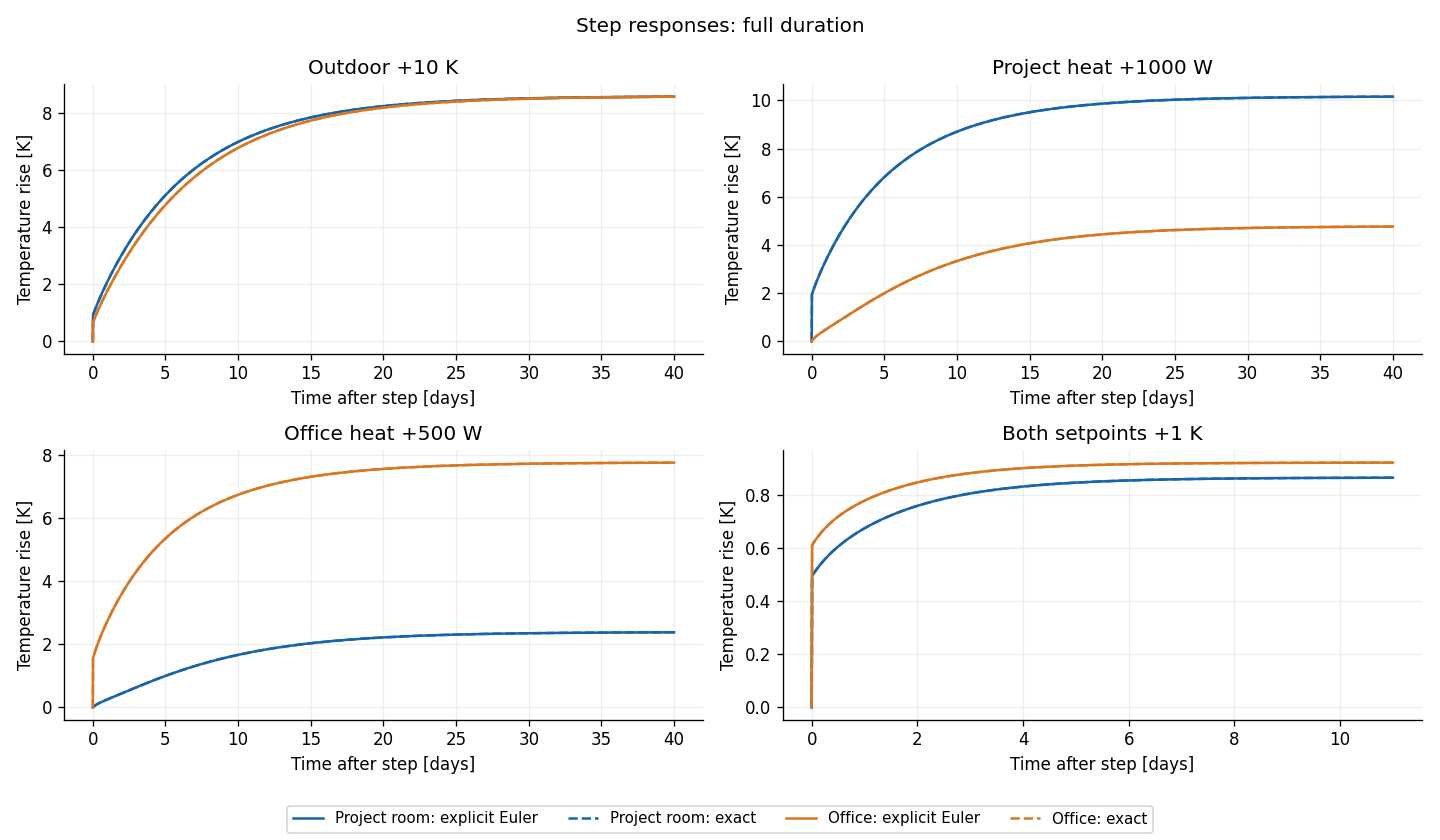

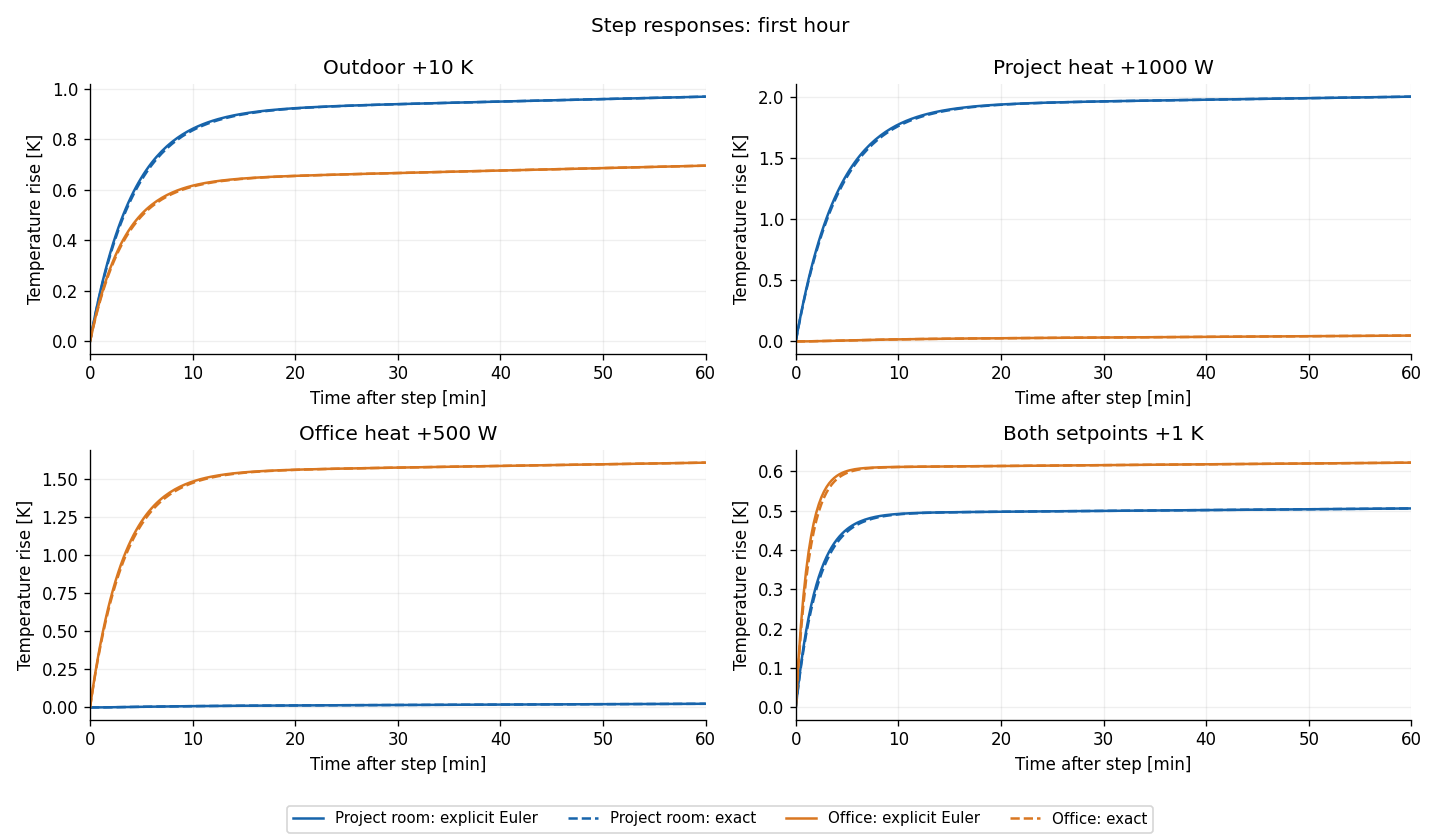

In [4]:
for first_hour in [False, True]:
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, (name, (time, explicit, exact, steady)) in zip(axes.flat, step_results.items()):
        selected = time <= 3600 if first_hour else slice(None, None, 40)
        plot_time = time[selected] / (60 if first_hour else 86400)
        for j, label in enumerate(zone_labels):
            ax.plot(plot_time, explicit[selected, j], color=colors[j],
                    label=label + ": explicit Euler")
            ax.plot(plot_time, exact[selected, j], color=colors[j], linestyle="--",
                    label=label + ": exact")
        ax.set(title=name, ylabel="Temperature rise [K]",
               xlabel="Time after step [min]" if first_hour else "Time after step [days]")
        if first_hour:
            ax.set_xlim(0, 60)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9)
    fig.suptitle("Step responses: first hour" if first_hour else "Step responses: full duration")
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

## 3. Conclusion

The air responds quickly, while the wall, roof, floor and partition masses react slower. A local heat input also warms the other room through the partition and door. The responses approach the equilibria calculated from $A_s x_\mathrm{ss}+B_s u=0$ and reported in the table above.

**Sources:** Christian Ghiaus, [03CubicBuilding.ipynb](https://github.com/cghiaus/dm4bem/blob/2eb8803cf038bd73c1618f2fd89771b9ba285ab4/03CubicBuilding.ipynb).
